In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from graphviz import Source

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from pathlib import Path

RAW_DATA_DIR = Path("RawData")


In [73]:
raw_a = pd.read_csv(
    RAW_DATA_DIR / "acc_exp01_user01.txt",
    sep=r"\s+",
    header=None
)

raw_g = pd.read_csv(
    RAW_DATA_DIR / "gyro_exp01_user01.txt",
    sep=r"\s+",
    header=None
)

labels = pd.read_csv(
    RAW_DATA_DIR / "labels.txt",
    sep=r"\s+",
    header=None,
    names=['exp', 'user', 'activity', 'start', 'end']
)


In [74]:
exp_label = labels[(labels['exp'] == 1) & (labels['user'] == 1)]


## load windows and labels

In [75]:
def load_windows_and_labels(sensor, exp_id, user_id, window_size=128):
    # Load raw signal
    if sensor == 'a':
        filename = RAW_DATA_DIR / f"acc_exp{exp_id:02d}_user{user_id:02d}.txt"
        raw = pd.read_csv(filename, sep=r"\s+", header=None)
        raw = raw.values
    elif sensor == 'g':
        filename = RAW_DATA_DIR / f"gyro_exp{exp_id:02d}_user{user_id:02d}.txt"
        raw = pd.read_csv(filename, sep=r"\s+", header=None)
        raw = raw.values

    # Cut into windows
    windows = []
    for start in range(0, len(raw) - window_size + 1, window_size):
        window = raw[start:start + window_size]
        windows.append(window)
    windows = np.array(windows)

    # Filter labels for current experiment/user
    exp_labels = labels[(labels['exp'] == exp_id) & (labels['user'] == user_id)]

    # Match each window to a label
    windows_label = []
    for start in range(0, len(raw) - window_size + 1, window_size):
        end = start + window_size
        match = exp_labels[(exp_labels['start'] <= start) & (exp_labels['end'] >= end)]
        if len(match) == 1:
            windows_label.append(match['activity'].values[0])
        else:
            windows_label.append(None)

    return windows, windows_label


In [76]:
def extract_features(windows):
    windows = np.asarray(windows) 

    means = windows.mean(axis=1)
    stds = windows.std(axis=1)
    maxs = windows.max(axis=1)
    return np.hstack([means, stds, maxs])



## process experiment

In [77]:
def process_experiment(exp_id, user_id):
    accl_windows, accl_labels = load_windows_and_labels('a',exp_id,user_id)
    gyro_windows, gyro_labels = load_windows_and_labels('g',exp_id,user_id)
    accl_features=extract_features(np.asarray(accl_windows))
    gyro_features=extract_features(np.asarray(gyro_windows))
    feature_names = ['a_mean_x', 'a_mean_y', 'a_mean_z',
                     'a_std_x', 'a_std_y', 'a_std_z',
                     'a_max_x', 'a_max_y', 'a_max_z',
                     'g_mean_x', 'g_mean_y', 'g_mean_z',
                     'g_std_x', 'g_std_y', 'g_std_z',
                     'g_max_x', 'g_max_y', 'g_max_z',
                     'label']
    df = pd.DataFrame(np.hstack([accl_features,gyro_features,np.asarray(accl_labels)[:,None]]), columns = feature_names)
    df.dropna(inplace=True)
    return df

In [78]:
pairs = labels[['exp','user']].drop_duplicates()

final = []
for exp_id , user_id in pairs.values:
    result = process_experiment(exp_id,user_id)
    final.append(result)

final_df = pd.concat(final,ignore_index=True)

feature_cols = final_df.columns[:-1]

final_df[feature_cols] = final_df[feature_cols].astype(float)
final_df['label'] = pd.to_numeric(
    final_df['label'],
    errors='coerce'
)


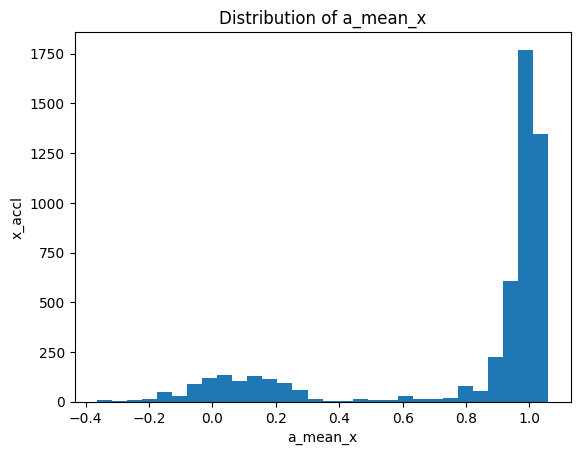

In [79]:
plt.hist(final_df['a_mean_x'],bins = 30)
plt.xlabel('a_mean_x')
plt.ylabel('x_accl')
plt.title('Distribution of a_mean_x')
plt.show()

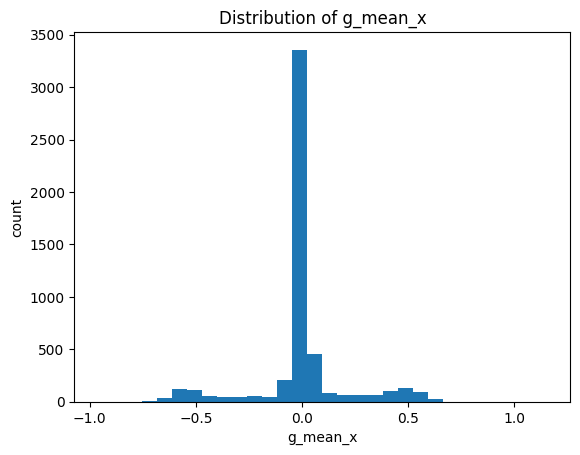

In [80]:
plt.hist(final_df['g_mean_x'],bins = 30)
plt.xlabel('g_mean_x')
plt.ylabel('count')
plt.title('Distribution of g_mean_x')
plt.show()

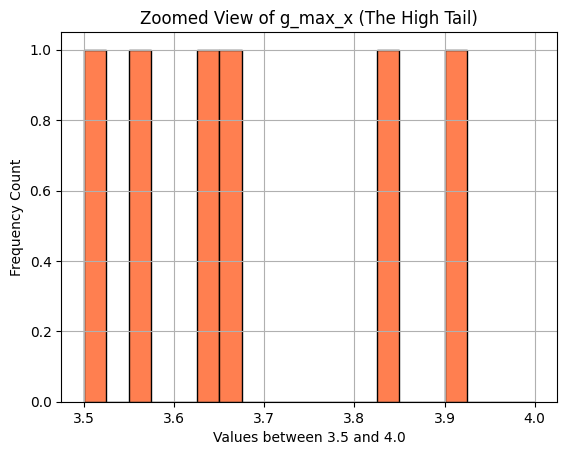

In [81]:
final_df['g_max_x'].hist(bins=20, range=(3.5, 4.0), color='coral', edgecolor='black')

plt.title('Zoomed View of g_max_x (The High Tail)')
plt.xlabel('Values between 3.5 and 4.0')
plt.ylabel('Frequency Count')
plt.show()


<Axes: ylabel='Count'>

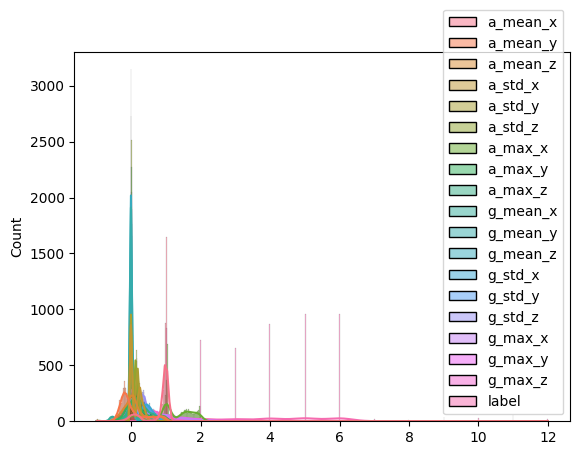

In [82]:

sns.histplot(final_df, kde=True)

<Axes: >

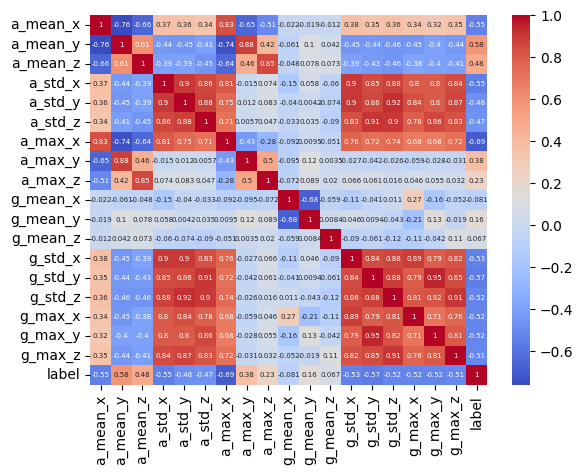

In [83]:
sns.heatmap(final_df.corr(), annot=True, cmap='coolwarm',annot_kws={"size": 5})

In [84]:
df = final_df[final_df['label']<=6]

In [85]:
x = df.drop('label', axis=1)
y = df['label']

In [86]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [87]:
scaler = joblib.load('scaler.pkl')
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)


In [88]:
y_train = y_train.astype('int')
y_test = y_test.astype('int')


print(np.mean(x_train_scaled, axis=0))
print(np.std(x_train_scaled, axis=0))

[-1.40332190e-16  3.01980663e-17  2.84217094e-17 -5.41788836e-17
 -1.11022302e-16 -2.02504680e-16  1.44773082e-16 -1.42108547e-17
 -7.01660952e-17 -3.10862447e-17 -1.86517468e-17  2.04281037e-17
  2.57571742e-17  1.95399252e-17 -9.68114477e-17 -7.19424520e-17
 -8.52651283e-17  3.55271368e-18]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Softmax regression

In [89]:
softmax_reg = LogisticRegression(random_state=42)

In [90]:
para_grid_reg = {
    'C':[0.01,0.1,1,10,100],
    'penalty':['l1','l2'],
    'solver':['liblinear','saga'],
}
grid_search_reg = GridSearchCV(
    estimator=softmax_reg,
    param_grid=para_grid_reg,
    cv =5,
    scoring = 'accuracy',
    n_jobs = -1
)

In [91]:
grid_search_reg.fit(x_train,y_train)
best_model_logit = grid_search_reg.best_estimator_

/home/rei/miniconda3/envs/ml_pyt/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(
/home/rei/miniconda3/envs/ml_pyt/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(
/home/rei/miniconda3/envs/ml_pyt/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised i

In [92]:
grid_search_reg.best_params_

{'C': 100, 'penalty': 'l1', 'solver': 'liblinear'}

In [93]:
y_pred_reg = best_model_logit.predict(x_test)


0.9193904952276754
0.918
0.9181831276926371
0.918


,penalty,'l1'
,dual,False
,tol,0.0001
,C,100
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'liblinear'
,max_iter,100
,multi_class,'deprecated'


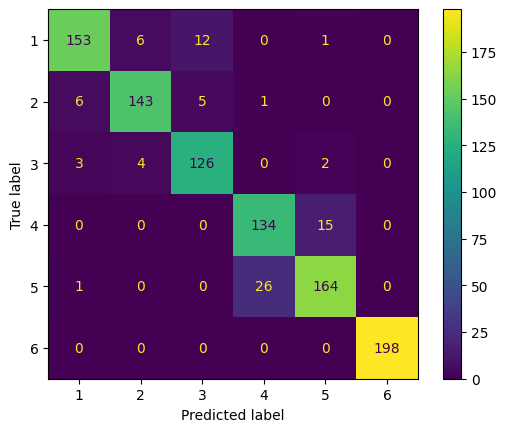

In [94]:
cm = confusion_matrix(y_test,y_pred_reg)
ConfusionMatrixDisplay(cm,display_labels=best_model_logit.classes_).plot()
print(precision_score(y_test,y_pred_reg,average='weighted'))
print(recall_score(y_test,y_pred_reg,average='weighted'))
print(f1_score(y_test,y_pred_reg,average='weighted'))
print(best_model_logit.score(x_test,y_test))
best_model_logit

## SVM

In [95]:
best_model_svm = joblib.load('svm_model.pkl')
y_pred_svm = best_model_svm.predict(x_test_scaled)

score_svm = accuracy_score(y_test, y_pred_svm)

print("SVM accuracy:", score_svm)

SVM accuracy: 0.963


0.9640031174598424
0.963
0.9631031582237732
0.963


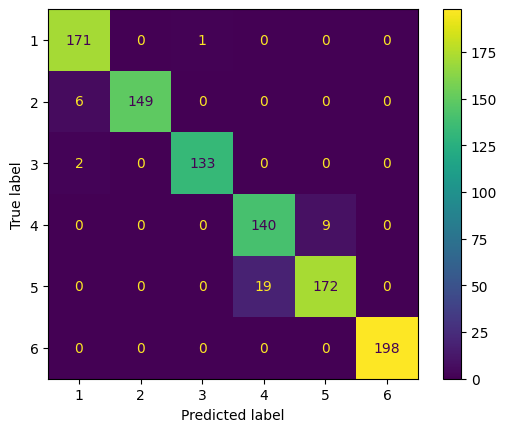

In [96]:
cm_svm = confusion_matrix(y_test, y_pred_svm)
ConfusionMatrixDisplay(
    cm_svm,
    display_labels=best_model_svm.classes_
).plot()

print(precision_score(
    y_test,
    y_pred_svm,
    average='weighted'
))

print(recall_score(
    y_test,
    y_pred_svm,
    average='weighted'
))

print(f1_score(
    y_test,
    y_pred_svm,
    average='weighted'
))

print(score_svm)


## Decision Tree

In [97]:

tree_clf = DecisionTreeClassifier(random_state=42)
para_grid_tree = {
    'criterion':['gini','entropy'],
    'max_depth':[None,1,2,3,4,5,6,7,8,9],
    'min_samples_split':[2,5,8,12,15,18,20,22],
    'min_samples_leaf':[1,2,3,4,5,6],
    'max_leaf_nodes':[9],
}
grid_search_tree = GridSearchCV(
    estimator=tree_clf,
    param_grid=para_grid_tree,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
)

In [98]:
grid_search_tree.fit(x_train,y_train)
best_model_tree= grid_search_tree.best_estimator_
best_model_tree

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,9
,min_impurity_decrease,0.0
,class_weight,None


In [99]:
export_graphviz(
    best_model_tree,
    out_file='har_tree.dot',
    feature_names=x.columns,
    class_names=[str(c) for c in best_model_tree.classes_],
    rounded= True,
    filled= True,
    )

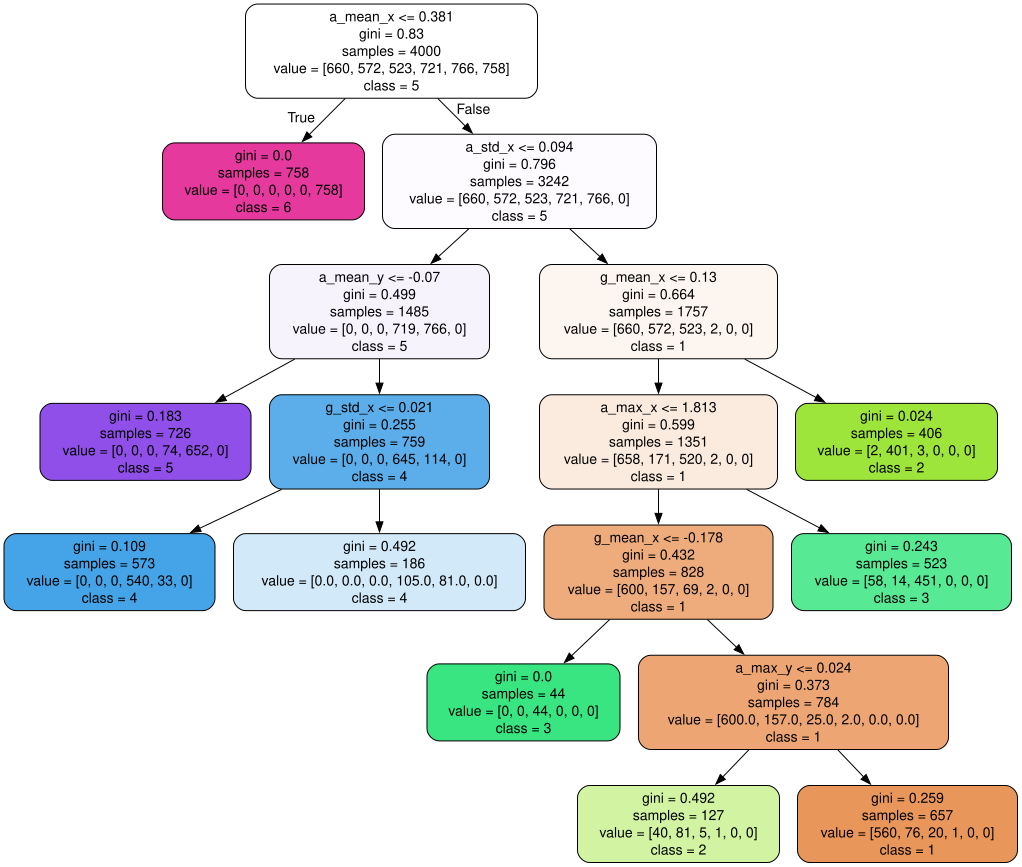

In [100]:
Source.from_file("har_tree.dot")

0.8849615951282874
0.882
0.8818838141923789
0.882


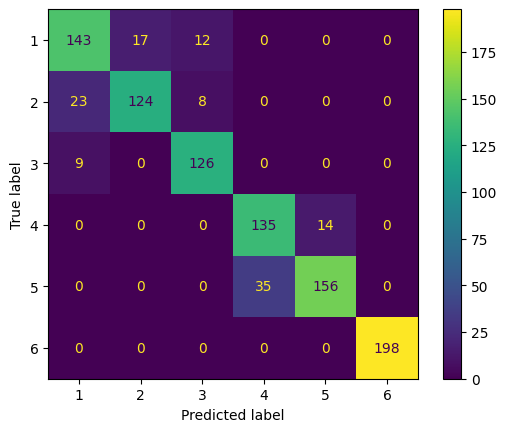

In [101]:
y_pred_tree = best_model_tree.predict(x_test)
score_tree = accuracy_score(y_test,y_pred_tree)
cm_tree = confusion_matrix(y_test,y_pred_tree)
ConfusionMatrixDisplay(cm_tree,display_labels=best_model_tree.classes_).plot()
print(precision_score(y_test,y_pred_tree,average='weighted'))
print(recall_score(y_test,y_pred_tree,average='weighted'))
print(f1_score(y_test,y_pred_tree,average='weighted'))
print(score_tree)


## Forest

In [103]:
best_model_forest = joblib.load('forest_model.pkl')
best_model_forest


,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [104]:
best_model_forest

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


0.9531085004823286
0.952
0.9520338879855752
0.952


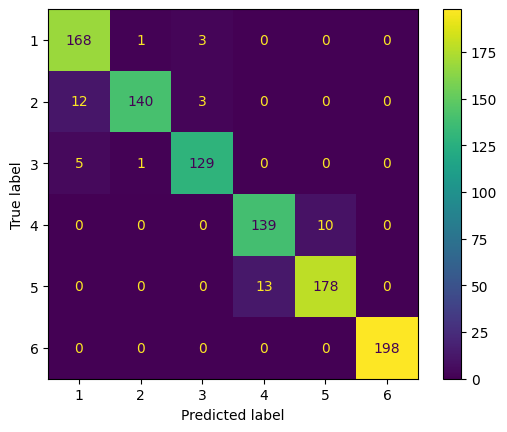

In [105]:
y_pred_forest = best_model_forest.predict(x_test)
score_forest = accuracy_score(y_test,y_pred_forest)
cm_forest = confusion_matrix(y_test,y_pred_forest)
ConfusionMatrixDisplay(cm_forest,display_labels=best_model_forest.classes_).plot()
print(precision_score(y_test,y_pred_forest,average='weighted'))
print(recall_score(y_test,y_pred_forest,average='weighted'))
print(f1_score(y_test,y_pred_forest,average='weighted'))
print(score_forest)

In [106]:
print("Forest accuracy:",
      accuracy_score(
          y_test,
          best_model_forest.predict(x_test)
      ))

Forest accuracy: 0.952


## sgd

In [107]:
sgd_clf = SGDClassifier(random_state=42)
para_grid_sgd = {
    'loss':['log_loss', 'hinge'],
    'penalty':['l1','l2','elasticnet'],
    'alpha':[1e-8,1e-7,1e-6,1e-5,1e-4,1e-3,1e-2,1e-1,],
    'learning_rate': ['optimal', 'adaptive'],
    'eta0': [0.01, 0.1] 
}

In [108]:
grid_search_sgd=GridSearchCV(
    estimator=sgd_clf,
    param_grid=para_grid_sgd,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

In [109]:
grid_search_sgd.fit(x_train,y_train)
best_model_sgd = grid_search_sgd.best_estimator_
best_model_sgd

,loss,'log_loss'
,penalty,'l1'
,alpha,1e-05
,l1_ratio,0.15
,fit_intercept,True
,max_iter,1000
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,n_jobs,None


0.9216993696415361
0.919
0.9190724157427818
0.919


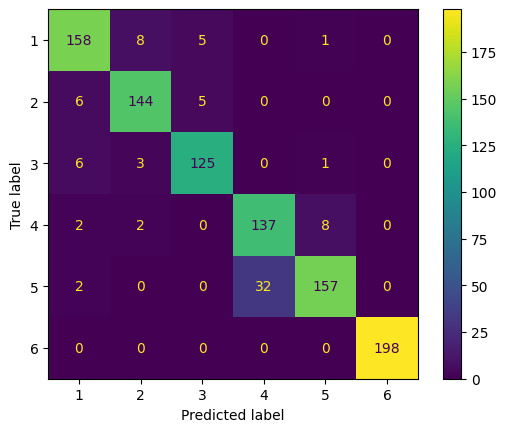

In [110]:
y_pred_sgd = best_model_sgd.predict(x_test)
score_sgd = accuracy_score(y_test,y_pred_sgd)
cm_sgd = confusion_matrix(y_test,y_pred_sgd)
ConfusionMatrixDisplay(cm_sgd,display_labels=best_model_sgd.classes_).plot()
print(precision_score(y_test,y_pred_sgd,average='weighted'))
print(recall_score(y_test,y_pred_sgd,average='weighted'))
print(f1_score(y_test,y_pred_sgd,average='weighted'))
print(score_sgd)

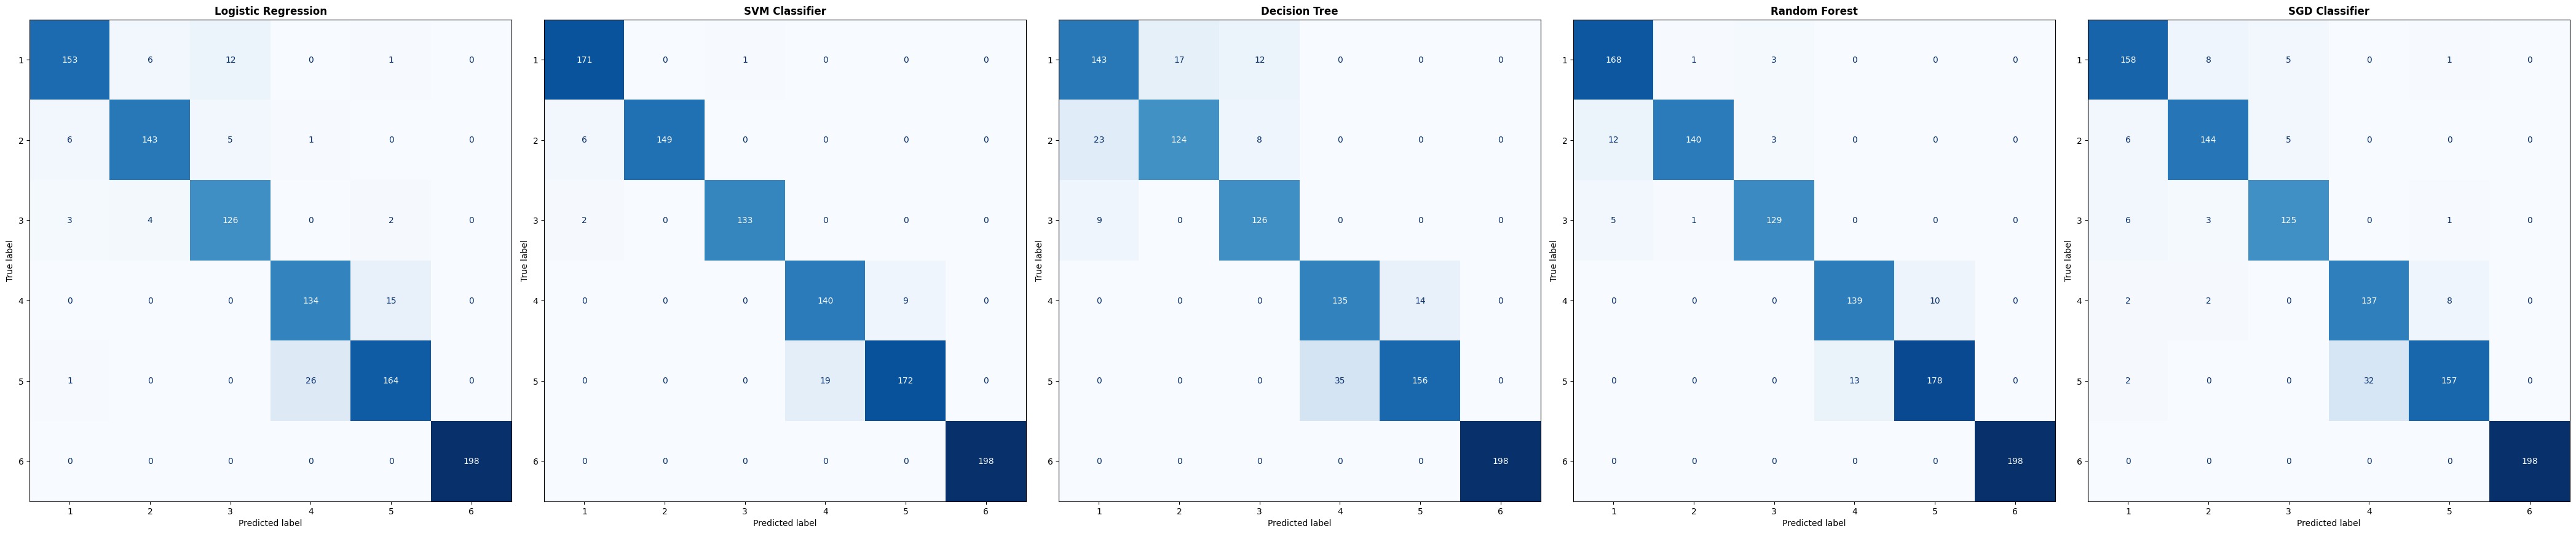

In [111]:
models = {
    "Logistic Regression": best_model_logit,
    "SVM Classifier": best_model_svm,
    "Decision Tree": best_model_tree,
    "Random Forest": best_model_forest,
    "SGD Classifier": best_model_sgd,
}

fig, axes = plt.subplots(
    nrows=1,
    ncols=5,
    figsize=(42, 16)
)

for i, (model_name, model_obj) in enumerate(models.items()):
    if model_name == "SVM Classifier":
        X_test_model = x_test_scaled
    else:
        X_test_model = x_test

    y_pred = model_obj.predict(X_test_model)

    ConfusionMatrixDisplay.from_predictions(
        y_true=y_test,
        y_pred=y_pred,
        ax=axes[i],
        cmap='Blues',
        colorbar=False
    )

    axes[i].set_title(
        model_name,
        fontsize=12,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()


# Experiment 1

In [112]:
def extract_features_with_mag(windows):
    windows = np.asarray(windows) 

    means = windows.mean(axis=1)
    stds = windows.std(axis=1)
    maxs = windows.max(axis=1)

    # mag of each time step
    mag = np.sqrt(np.sum(windows**2,axis=2))
    mag_mean = mag.mean(axis=1)
    mag_std = mag.std(axis=1)
    mag_max = mag.max(axis=1)

    return np.hstack([means,
                     stds, 
                     maxs,
                     mag_mean[:,None],
                     mag_std[:, None],
                     mag_max[:, None]]
                     )



In [113]:
def process_experiment_with_mag(exp_id, user_id):
    accl_windows, accl_labels = load_windows_and_labels('a',exp_id,user_id)
    gyro_windows, gyro_labels = load_windows_and_labels('g',exp_id,user_id)
    accl_features=extract_features_with_mag(np.asarray(accl_windows))
    gyro_features=extract_features_with_mag(np.asarray(gyro_windows))
    feature_names = ['a_mean_x', 'a_mean_y', 'a_mean_z',
                     'a_std_x', 'a_std_y', 'a_std_z',
                     'a_max_x', 'a_max_y', 'a_max_z',

                     'a_mag_mean', 'a_mag_std', 'a_mag_max',

                     'g_mean_x', 'g_mean_y', 'g_mean_z',
                     'g_std_x', 'g_std_y', 'g_std_z',
                     'g_max_x', 'g_max_y', 'g_max_z',

                     'g_mag_mean', 'g_mag_std', 'g_mag_max',

                     'label']
    df = pd.DataFrame(np.hstack([accl_features,gyro_features,np.asarray(accl_labels)[:,None]]), columns = feature_names)
    df.dropna(inplace=True)
    return df

In [114]:
final_mag = []

for exp_id, user_id in pairs.values:
    result = process_experiment_with_mag(exp_id, user_id)
    final_mag.append(result)

final_df_mag = pd.concat(final_mag, ignore_index=True)
print(final_df_mag.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5168 entries, 0 to 5167
Data columns (total 25 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   a_mean_x    5168 non-null   object
 1   a_mean_y    5168 non-null   object
 2   a_mean_z    5168 non-null   object
 3   a_std_x     5168 non-null   object
 4   a_std_y     5168 non-null   object
 5   a_std_z     5168 non-null   object
 6   a_max_x     5168 non-null   object
 7   a_max_y     5168 non-null   object
 8   a_max_z     5168 non-null   object
 9   a_mag_mean  5168 non-null   object
 10  a_mag_std   5168 non-null   object
 11  a_mag_max   5168 non-null   object
 12  g_mean_x    5168 non-null   object
 13  g_mean_y    5168 non-null   object
 14  g_mean_z    5168 non-null   object
 15  g_std_x     5168 non-null   object
 16  g_std_y     5168 non-null   object
 17  g_std_z     5168 non-null   object
 18  g_max_x     5168 non-null   object
 19  g_max_y     5168 non-null   object
 20  g_max_z 

In [115]:
df_mag = final_df_mag[final_df_mag['label']<=6 ]


In [116]:
x_mag = df_mag.drop('label', axis=1)
y_mag = df_mag['label']

In [117]:
x_mag_train, x_mag_test, y_mag_train, y_mag_test = train_test_split(
    x_mag,
    y_mag,
    test_size=0.2,
    random_state=42
)

y_mag_train = y_mag_train.astype(int)
y_mag_test = y_mag_test.astype(int)


In [118]:
std_scaler_mag =joblib.load('scaler_mag.pkl')

# x_train_mag_scaled = std_scaler_mag.fit_transform(x_mag_train)
x_test_mag_scaled = std_scaler_mag.transform(x_mag_test)
best_model_mag = joblib.load('svm_magnitude_model.pkl')


### Saved Experiment Model

The magnitude-feature SVM was trained using GridSearchCV with the parameter grid defined above. Since the training process has already been completed, the trained model and its corresponding scaler are loaded from saved `.pkl` files for evaluation and reproducibility.

The saved artifacts are:

- `svm_magnitude_model.pkl`
- `scaler_mag.pkl`

In [119]:
para_grid_svm = {
    'C':[0.01,0.1,1,10,100],
    'kernel':['linear','rbf','poly','sigmoid'],
    'gamma':['scale', 'auto']
}


0.9616479891416739
0.961
0.9610282341524224
0.961


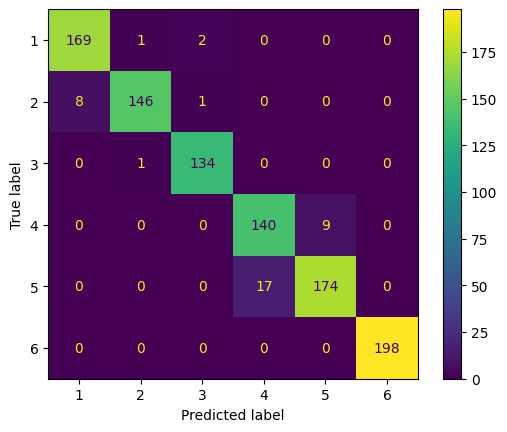

In [120]:
y_pred_mag = best_model_mag.predict(x_test_mag_scaled)
score_mag = accuracy_score(y_mag_test,y_pred_mag)
cm_mag = confusion_matrix(y_mag_test,y_pred_mag)
ConfusionMatrixDisplay(cm_mag,display_labels=best_model_mag.classes_).plot()
print(precision_score(y_mag_test,y_pred_mag,average='weighted'))
print(recall_score(y_mag_test,y_pred_mag,average='weighted'))
print(f1_score(y_mag_test,y_pred_mag,average='weighted'))
print(score_mag)

## Feature Engineering Experiment — Magnitude Features

As a feature engineering experiment, six additional magnitude-based features were added:

- `a_mag_mean`
- `a_mag_std`
- `a_mag_max`
- `g_mag_mean`
- `g_mag_std`
- `g_mag_max`

This increased the feature count from 18 to 24.

The same train/test split, StandardScaler preprocessing, and SVM hyperparameter search were used to make the comparison controlled.

| Representation | Features | Train Accuracy | Test Accuracy |
|---|---:|---:|---:|
| Original | 18 | 97.28% | **96.30%** |
| With Magnitude Features | 24 | 97.13% | 96.10% |

The magnitude features produced a slight decrease in test accuracy. Therefore, they were not included in the final model.

The experiment demonstrates that additional features do not necessarily improve model performance.